# Judge Response Theory (JRT)

**Idea.** Myszkowski & Storme (2019) proposed treating judges in creativity
assessment like **items in an IRT model**: each judge is a measurement
instrument with its own characteristics. Besides leniency, a judge has a
**discrimination** $a_j$, which says how sharply their ratings separate more
from less creative products. JRT lets the most informative judges count more,
and quantifies how much information each judge contributes at each level of
creativity.

**This notebook computes**
- a graded-response JRT model with rater-specific discrimination and leniency
  and shared thresholds (Bayesian, PyMC), with full convergence diagnostics and
  posterior predictive checks,
- the nested equal-discrimination model (all $a_j$ equal), fitted here with the
  same parameterisation, and a PSIS-LOO comparison of the two,
- judge category curves and graded-response information functions,
- the marginal reliability of θ as a function of the number of judges (an IRT
  D-study), and the empirical reliability of the scores.

The notebook is self-contained: it needs only the cleaned data from
`00_data_loading_preprocessing.ipynb`.

**Assumptions and limits.** The full JRT/GRM gives every judge their own
thresholds $b_{jk}$. With the present sparse overlap between raters, that would
add many weakly identified parameters, so the thresholds are shared here; the
assumption of a common category structure is therefore not tested.

**Outputs:** `results/tables/scores_jrt.csv`, `raters_jrt.csv`,
`model_diagnostics_jrt.csv`, `jrt_*.csv`, `results/figures/fig_jrt_*`,
`results/models/jrt_discrimination_model.nc`, `jrt_equal_discrimination_model.nc`.

## 0. Setup, reproducibility, and session information

In [1]:
import warnings
import platform
import subprocess
import sys
import json
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

NOTEBOOK_KEY = "jrt"
SEED = 20260713
np.random.seed(SEED)
rng = np.random.default_rng(SEED)

# ------------------------------------------------------------------
# Project paths (relative to the notebook folder "notebooks/")
# ------------------------------------------------------------------
PROJECT_ROOT = Path("..").resolve()
DATA_RAW = PROJECT_ROOT / "data" / "raw"
DATA_PROCESSED = PROJECT_ROOT / "data" / "processed"
RESULTS_TABLES = PROJECT_ROOT / "results" / "tables"
RESULTS_FIGURES = PROJECT_ROOT / "results" / "figures"
RESULTS_MODELS = PROJECT_ROOT / "results" / "models"
RESULTS_LOGS = PROJECT_ROOT / "results" / "logs"

for d in [DATA_PROCESSED, RESULTS_TABLES, RESULTS_FIGURES, RESULTS_MODELS, RESULTS_LOGS]:
    d.mkdir(parents=True, exist_ok=True)

plt.rcParams["figure.dpi"] = 110
plt.rcParams["savefig.dpi"] = 200
plt.rcParams["font.size"] = 10
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

warnings.filterwarnings("default", category=UserWarning)

def save_fig(fig, name, caption=None):
    # Saves a figure as PNG and SVG under results/figures/.
    fig.savefig(RESULTS_FIGURES / f"{name}.png", bbox_inches="tight")
    fig.savefig(RESULTS_FIGURES / f"{name}.svg", bbox_inches="tight")
    if caption:
        (RESULTS_FIGURES / f"{name}_caption.txt").write_text(caption)

def save_table(df_table, name, index=False):
    # Saves a table as CSV under results/tables/.
    path = RESULTS_TABLES / f"{name}.csv"
    df_table.to_csv(path, index=index)
    return path

def save_diagnostics(values):
    # Scalar results (reliability, convergence, ...) for 03_approach_comparison.ipynb.
    out = pd.DataFrame({"quantity": list(values), "value": [float(v) for v in values.values()]})
    return save_table(out, f"model_diagnostics_{NOTEBOOK_KEY}")

WARNINGS_LOG = []
def log_warning(msg):
    # No silent failures: warnings are collected and exported at the end of the notebook.
    WARNINGS_LOG.append({"notebook": NOTEBOOK_KEY,
                         "timestamp": datetime.now(timezone.utc).isoformat(),
                         "message": msg})
    warnings.warn(msg)

from IPython.display import Markdown

def show_table(df_table, digits=3):
    # Markdown table without the index column, for embedding in the manuscript.
    return Markdown(df_table.to_markdown(index=False, floatfmt=f".{digits}f"))

print(f"Seed: {SEED}")
print(f"Project root: {PROJECT_ROOT}")

Seed: 20260713
Project root: /home/mklemp/jrt


In [2]:
def get_git_hash():
    try:
        out = subprocess.run(["git", "rev-parse", "HEAD"], cwd=PROJECT_ROOT,
                             capture_output=True, text=True, timeout=5)
        if out.returncode == 0:
            return out.stdout.strip()
    except Exception:
        pass
    return "not available"

session_info = {
    "notebook": NOTEBOOK_KEY,
    "analysis_datetime_utc": datetime.now(timezone.utc).isoformat(),
    "python_version": sys.version,
    "platform": platform.platform(),
    "git_commit": get_git_hash(),
    "seed": SEED,
    "package_versions": {},
}
for pkg_name in ['numpy', 'pandas', 'scipy', 'matplotlib', 'networkx', 'pymc', 'arviz']:
    try:
        mod = __import__(pkg_name)
        session_info["package_versions"][pkg_name] = getattr(mod, "__version__", "unknown")
    except ImportError:
        session_info["package_versions"][pkg_name] = "not installed"

with open(RESULTS_LOGS / f"session_info_{NOTEBOOK_KEY}.json", "w") as f:
    json.dump(session_info, f, indent=2)
print(json.dumps(session_info["package_versions"], indent=2))

{
  "numpy": "2.4.6",
  "pandas": "3.0.3",
  "scipy": "1.18.0",
  "matplotlib": "3.11.0",
  "networkx": "3.6.1",
  "pymc": "6.1.0",
  "arviz": "1.2.0"
}


## 1. Data

Loads the cleaned ratings from `00_data_loading_preprocessing.ipynb`
(`data/processed/ratings_long_clean.csv`) and flags the largest connected
component of the rater–action graph.

In [3]:
CLEAN_PATH = DATA_PROCESSED / "ratings_long_clean.csv"
if not CLEAN_PATH.exists():
    raise FileNotFoundError(f"{CLEAN_PATH} not found. Run 00_data_loading_preprocessing.ipynb first.")

ratings_clean = pd.read_csv(CLEAN_PATH)
ratings_clean["action_id"] = ratings_clean["action_id"].astype(str)
ratings_clean["rater_id"] = ratings_clean["rater_id"].astype(str)

required_cols = ["action_id", "rater_id", "rating_numeric"]
missing_cols = [c for c in required_cols if c not in ratings_clean.columns]
if missing_cols:
    raise ValueError(f"Required variables missing from the preprocessed dataset: {missing_cols}")
assert ratings_clean["rating_numeric"].between(1, 7).all(), "Ratings outside 1-7!"
assert not ratings_clean.duplicated(subset=["action_id", "rater_id"]).any(), "Duplicate (action_id, rater_id) rows!"

ratings_per_action = ratings_clean.groupby("action_id").size().rename("n_ratings")
n_raters = ratings_clean["rater_id"].nunique()
print(f"Loaded {len(ratings_clean)} ratings ({ratings_clean['action_id'].nunique()} actions, "
      f"{n_raters} raters).")
ratings_clean.head()

Loaded 7844 ratings (3669 actions, 22 raters).


,rater_id,action_id,rating,technical_correctness,aesthetic_appeal,timestamp,rating_numeric,rating_ordinal,rating_order
0,R04,0786bb62-2032-444b-ac1f-59fa165dbb71,1.0,2.0,2.0,2026-03-11 11:50:29.717,1,1,5
1,R03,f90addfa-4cf8-4b07-a4eb-9ee7ff757519,2.0,4.0,1.0,2025-11-18 12:26:15.275,2,2,708
2,R03,2bdc8133-ac12-45f1-9104-882873efa7bf,3.0,4.0,2.0,2025-10-15 13:35:18.000,3,3,17
3,R09,938d2c93-5e6f-442e-ba7c-f92c53080a42,5.0,5.0,5.0,2026-05-05 15:58:08.508,5,5,6
4,R04,4fe7a32b-09ce-466b-9772-494ed03ea493,6.0,7.0,7.0,2026-04-08 13:56:06.665,6,6,403


In [4]:
# Connected components of the bipartite rater-action graph. Rater severity is only
# identifiable within a component; full design diagnostics are in 01_data_overview.ipynb.
B = nx.Graph()
B.add_edges_from(zip(ratings_clean["action_id"], "R::" + ratings_clean["rater_id"]))
components = sorted(nx.connected_components(B), key=len, reverse=True)
n_components = len(components)

action_component_map = {n: i for i, comp in enumerate(components)
                        for n in comp if not str(n).startswith("R::")}
ratings_clean["connected_component"] = ratings_clean["action_id"].map(action_component_map)
ratings_clean["in_largest_component"] = ratings_clean["connected_component"] == 0
largest_component_actions = set(ratings_clean.loc[ratings_clean["in_largest_component"], "action_id"])
largest_component_raters = set(ratings_clean.loc[ratings_clean["in_largest_component"], "rater_id"])

print(f"Connected components: {n_components}; largest: {len(largest_component_actions)} actions, "
      f"{len(largest_component_raters)} raters.")
if n_components > 1:
    log_warning(f"The rater-action graph has {n_components} components; rater-correcting "
                "models are estimated on the largest one only.")

Connected components: 1; largest: 3669 actions, 22 raters.


## 2. Model

### 2.1 Concept

Judge Response Theory (Myszkowski & Storme, 2019) transfers polytomous
IRT models to judgment data: raters are treated as measurement
instruments ("items"), actions as the objects being measured. One
graded-response form is:

$$
P(Y_{ij}\ge k \mid \theta_i) = \operatorname{logit}^{-1}
\left[a_j(\theta_i-b_{jk})\right]
$$

with $\theta_i$ = creativity of action $i$, $a_j$ = **discrimination**
of rater $j$ (how strongly does rater $j$ differentiate between
actions?), $b_{jk}$ = rater-specific threshold for category $k$. A
many-facet Rasch model assumes equal discrimination for all raters; JRT
allows rater-specific discrimination.

### 2.2 Constrained, identifiable variant

Full rater-specific thresholds $b_{jk}$ (6 per rater) cannot be estimated with
sufficient precision given the present connectivity (see the overlap
diagnostics in `01_data_overview.ipynb`). We therefore estimate a **reduced JRT
variant** with rater-specific discrimination at **global** thresholds:

$$
\eta_{ij} = a_j \cdot \theta_i + \lambda_j, \qquad
\Pr(Y_{ij}\le k) = \operatorname{logit}^{-1}(\tau_k - \eta_{ij})
$$

$\lambda_j$ is the rater's **leniency**: a higher $\lambda_j$ shifts all of
rater $j$'s ratings upwards.

**Identification.**
- *Scale:* $a_j\cdot\theta_i$ is invariant to $a_j\cdot c$, $\theta_i/c$, so
  $\theta_i \sim \mathcal N(0,1)$ is fixed exactly, and
  $\log a_j \sim \mathcal N(\mu_{\log a}, \sigma_{\log a})$ is free.
- *Location:* a common shift of all $\lambda_j$ can be absorbed by the
  thresholds $\tau_k$. The leniencies are therefore constrained to sum to zero
  (`ZeroSumNormal`), so $\lambda_j$ is the leniency **relative to the average
  rater**, and the thresholds are identified.

**Priors.** $\mu_{\log a}\sim\mathcal N(0,1)$,
$\sigma_{\log a}\sim\text{Exp}(2)$, $\sigma_\lambda\sim\text{Exp}(1)$,
$\tau_k\sim\mathcal N(\text{linspace}(-2.5, 2.5), 1.5)$ with an ordering
constraint.

**Nested model.** Setting $\sigma_{\log a}=0$ gives the equal-discrimination
model ($a_j = a$ for all raters), with everything else unchanged. Both models
are built by the same function below, so the nesting is exact.

In [5]:
import pymc as pm
import arviz as az

df_ord = ratings_clean.loc[ratings_clean["in_largest_component"]].copy()
action_idx_o, action_levels_o = pd.factorize(df_ord["action_id"])
rater_idx_o, rater_levels_o = pd.factorize(df_ord["rater_id"])
y_ord = (df_ord["rating_numeric"].values.astype(int) - 1)  # 0-based for PyMC

print(f"Ordinal model: {len(y_ord)} ratings, {len(action_levels_o)} actions, "
      f"{len(rater_levels_o)} raters.")
print(f"Category frequencies (0-based): {np.bincount(y_ord, minlength=7)}")

Ordinal model: 7844 ratings, 3669 actions, 22 raters.
Category frequencies (0-based): [2034 2116 1471 1045  728  341  109]


In [6]:
import pytensor.tensor as pt

import os

# Sampler settings; JRT_DRAWS / JRT_TUNE override them for a quick smoke test
# (see server/run_jrt_server.sh). Results for the paper use the defaults.
N_DRAWS = int(os.environ.get("JRT_DRAWS", 2000))
N_TUNE = int(os.environ.get("JRT_TUNE", 2000))
N_CHAINS, TARGET_ACCEPT = 4, 0.95
# JRT_USE_SAVED_FITS=1 reloads the fits in results/models/ instead of sampling again
# (e.g. after the server run); all downstream cells are re-computed from them.
USE_SAVED_FITS = os.environ.get("JRT_USE_SAVED_FITS", "0") == "1"

def build_jrt_model(equal_discrimination=False):
    coords = {"action": action_levels_o, "rater": rater_levels_o, "cut": range(6)}
    with pm.Model(coords=coords) as model:
        theta = pm.Normal("theta", 0, 1, dims="action")  # fixed scale: Var(theta) = 1

        sigma_lambda = pm.Exponential("sigma_lambda", 1.0)
        lam = pm.ZeroSumNormal("leniency", sigma=sigma_lambda, dims="rater")

        mu_log_a = pm.Normal("mu_log_a", 0, 1)
        if equal_discrimination:
            log_a = pm.Deterministic("log_a", mu_log_a + pt.zeros(len(rater_levels_o)), dims="rater")
        else:
            sigma_log_a = pm.Exponential("sigma_log_a", 2.0)
            log_a_raw = pm.Normal("log_a_raw", 0, 1, dims="rater")
            log_a = pm.Deterministic("log_a", mu_log_a + log_a_raw * sigma_log_a, dims="rater")
        a_j = pm.Deterministic("discrimination", pm.math.exp(log_a), dims="rater")

        cutpoints = pm.Normal(
            "cutpoints", mu=np.linspace(-2.5, 2.5, 6), sigma=1.5,
            transform=pm.distributions.transforms.ordered, dims="cut",
        )
        # Note: no initval= (it breaks pm.compute_log_likelihood for ordered transforms).

        eta = a_j[rater_idx_o] * theta[action_idx_o] + lam[rater_idx_o]
        pm.OrderedLogistic("y_obs", eta=eta, cutpoints=cutpoints, observed=y_ord)
    return model

def shrink_log_likelihood(idata):
    # Pointwise log-likelihood (n_draws x n_ratings) is the largest array; float32 halves it.
    ll = idata["log_likelihood"]
    idata["log_likelihood"] = (ll.to_dataset() if hasattr(ll, "to_dataset") else ll).astype("float32")
    return idata

JRT_FIT_PATH = RESULTS_MODELS / "jrt_discrimination_model.nc"
jrt_model = build_jrt_model(equal_discrimination=False)
if USE_SAVED_FITS:
    idata_jrt = az.from_netcdf(str(JRT_FIT_PATH))
    N_CHAINS, N_DRAWS = idata_jrt.posterior.sizes["chain"], idata_jrt.posterior.sizes["draw"]
    print(f"Loaded saved fit: {JRT_FIT_PATH.name}")
else:
    with jrt_model:
        idata_jrt = pm.sample(draws=N_DRAWS, tune=N_TUNE, chains=N_CHAINS, cores=N_CHAINS,
                              target_accept=TARGET_ACCEPT, random_seed=SEED, progressbar=False)
        pm.compute_log_likelihood(idata_jrt, progressbar=False)
    idata_jrt = shrink_log_likelihood(idata_jrt)
    idata_jrt.to_netcdf(str(JRT_FIT_PATH))
    print(f"Model saved: results/models/{JRT_FIT_PATH.name}")
print(f"Sampler: {N_CHAINS} chains x {N_DRAWS} draws after {N_TUNE} tuning steps, "
      f"target_accept = {TARGET_ACCEPT}")

Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [theta, sigma_lambda, leniency, mu_log_a, sigma_log_a, log_a_raw, cutpoints]


Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 511 seconds.


Sampler: 4 chains x 2000 draws after 2000 tuning steps, target_accept = 0.95
Model saved: results/models/jrt_discrimination_model.nc


## 3. Diagnostics and rater parameters

Convergence is checked for **every** parameter group (actions θ, rater
leniency λ and discrimination $a_j$, thresholds, hyperparameters): split
$\hat R < 1.01$, bulk and tail ESS > 400, and no divergent transitions
(Vehtari et al., 2021). Discrimination $a_j$ and leniency $\lambda_j$ are
reported with 95% credible intervals. Because θ has a fixed N(0, 1) scale,
$a_j$ is compared with the pool discrimination $\exp(\mu_{\log a})$: a rater
whose interval for $\log a_j - \mu_{\log a}$ excludes 0 discriminates more
(or less) sharply than the typical rater.

In [7]:
PARAM_GROUPS = {
    "action creativity (theta)": ["theta"],
    "rater leniency (lambda_j)": ["leniency"],
    "rater discrimination (a_j)": ["discrimination"],
    "thresholds (tau_k)": ["cutpoints"],
    "hyperparameters": ["sigma_lambda", "mu_log_a", "sigma_log_a"],
}

def convergence_by_group(idata, groups):
    rows, summaries = [], {}
    available = set(idata.posterior.data_vars)
    for group, var_names in groups.items():
        var_names = [v for v in var_names if v in available]
        if not var_names:
            continue
        s = az.summary(idata, var_names=var_names, round_to=6)
        summaries[group] = s
        rows.append({"parameter_group": group, "n_parameters": len(s),
                     "max_r_hat": float(s["r_hat"].max()),
                     "min_ess_bulk": float(s["ess_bulk"].min()),
                     "min_ess_tail": float(s["ess_tail"].min())})
    return pd.DataFrame(rows), summaries

conv_jrt, summaries_jrt = convergence_by_group(idata_jrt, PARAM_GROUPS)
n_div_jrt = int(idata_jrt.sample_stats["diverging"].sum())
max_rhat_jrt = float(conv_jrt["max_r_hat"].max())
min_ess_jrt = float(conv_jrt["min_ess_bulk"].min())
min_ess_tail_jrt = float(conv_jrt["min_ess_tail"].min())
save_table(conv_jrt, "jrt_convergence_by_group")

summary_jrt = pd.concat([summaries_jrt["thresholds (tau_k)"], summaries_jrt["hyperparameters"]])
save_table(summary_jrt.reset_index().rename(columns={"index": "parameter"}), "jrt_model_summary")

print(f"Divergences: {n_div_jrt}, max R-hat: {max_rhat_jrt:.4f}, "
      f"min bulk ESS: {min_ess_jrt:.0f}, min tail ESS: {min_ess_tail_jrt:.0f}")
if max_rhat_jrt >= 1.01:
    log_warning(f"Max R-hat = {max_rhat_jrt:.4f} >= 1.01 for the JRT model.")
if min(min_ess_jrt, min_ess_tail_jrt) < 400:
    log_warning(f"Min ESS (bulk {min_ess_jrt:.0f}, tail {min_ess_tail_jrt:.0f}) < 400 for the JRT model.")
if n_div_jrt > 0:
    log_warning(f"{n_div_jrt} divergences in the JRT model.")

Table saved: results/tables/jrt_convergence_by_group.csv (5 rows x 5 columns)
Table saved: results/tables/jrt_model_summary.csv (9 rows x 10 columns)
Divergences: 0, max R-hat: 1.0048, min bulk ESS: 2014, min tail ESS: 3034


,parameter_group,n_parameters,max_r_hat,min_ess_bulk,min_ess_tail
0,action creativity (theta),3669,1.004775,14092.959882,4132.096533
1,rater leniency (lambda_j),22,1.000823,4171.442450,5636.115711
2,rater discrimination (a_j),22,1.002028,2940.414765,4457.720773
3,thresholds (tau_k),6,1.001618,3445.797577,4534.336847
4,hyperparameters,3,1.001461,2014.040992,3033.626914


In [ ]:
#| label: tbl-jrt-convergence
#| tbl-cap: "Convergence diagnostics of the JRT model by parameter group: largest split R-hat, smallest bulk and tail effective sample size, and number of parameters."
show_table(conv_jrt, 4)

In [8]:
#| label: tbl-jrt-model-summary
#| tbl-cap: "Posterior summaries of the JRT thresholds and hyperparameters."
show_table(summary_jrt.reset_index().rename(columns={"index": "parameter"})[["parameter", "mean", "sd", "ess_bulk", "ess_tail", "r_hat"]], 3)

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
cutpoints[0],-2.253360,0.087836,-2.393261,-2.114741,3445.797577,4534.336847,1.001618,0.001496,0.001049
cutpoints[1],-0.200214,0.082279,-0.333650,-0.069299,3532.699459,4958.535732,1.001511,0.001383,0.000984
cutpoints[2],1.230700,0.083471,1.097960,1.364848,3919.306183,5365.775528,1.001455,0.001334,0.000972
cutpoints[3],2.579319,0.089684,2.437743,2.722816,4188.749061,5457.528095,1.001210,0.001385,0.001001
cutpoints[4],4.253115,0.108634,4.081734,4.427186,4901.381096,5413.471024,1.001409,0.001552,0.001122
cutpoints[5],6.441121,0.166129,6.177749,6.712673,6407.521589,5666.343358,1.000734,0.002068,0.001514
sigma_lambda,1.232476,0.198034,0.956799,1.583755,13678.210075,5966.578547,0.999898,0.001869,0.001615
mu_log_a,0.622311,0.091910,0.473327,0.765465,2014.040992,3033.626914,1.001461,0.002047,0.001548
sigma_log_a,0.388639,0.077641,0.281909,0.521657,3070.046766,4007.828014,1.000855,0.001380,0.001319


In [9]:
def post_stats(var):
    da = idata_jrt.posterior[var]
    return (da.mean(dim=("chain", "draw")).values,
            da.quantile(0.025, dim=("chain", "draw")).values,
            da.quantile(0.975, dim=("chain", "draw")).values,
            da.std(dim=("chain", "draw")).values)

disc, disc_low, disc_high, disc_sd = post_stats("discrimination")
# Deviation of each rater's log-discrimination from the pool mean mu_log_a.
log_a_dev = idata_jrt.posterior["log_a"] - idata_jrt.posterior["mu_log_a"]
log_a_dev_low = log_a_dev.quantile(0.025, dim=("chain", "draw")).values
log_a_dev_high = log_a_dev.quantile(0.975, dim=("chain", "draw")).values
a_pool = float(np.exp(idata_jrt.posterior["mu_log_a"]).median())
len_mean, len_low, len_high, len_sd = post_stats("leniency")
jrt_rater_table = pd.DataFrame({
    "rater_id": rater_levels_o,
    "n_ratings": df_ord.groupby("rater_id").size().reindex(rater_levels_o).values,
    "discrimination": disc, "discrimination_lower": disc_low,
    "discrimination_upper": disc_high, "discrimination_se": disc_sd,
    "leniency": len_mean, "leniency_lower": len_low,
    "leniency_upper": len_high, "leniency_se": len_sd,
    "log_discrimination_vs_pool_lower": log_a_dev_low,
    "log_discrimination_vs_pool_upper": log_a_dev_high,
}).sort_values("rater_id").reset_index(drop=True)
save_table(jrt_rater_table, "jrt_rater_table")

print(f"Discrimination: median={np.median(disc):.2f}, range=[{disc.min():.2f}, {disc.max():.2f}], "
      f"pool exp(mu_log_a) = {a_pool:.2f}")
print("Raters with noticeably low discrimination (< 0.5): "
      f"{(disc < 0.5).sum()}")
print(f"Leniency: range=[{len_mean.min():.2f}, {len_mean.max():.2f}]")

Table saved: results/tables/jrt_rater_table.csv (22 rows x 12 columns)
Discrimination: median=2.08, range=[0.96, 3.24], pool exp(mu_log_a) = 1.87
Raters with noticeably low discrimination (< 0.5): 0
Leniency: range=[-2.93, 1.63]


,rater_id,n_ratings,discrimination,discrimination_lower,discrimination_upper,discrimination_se,leniency,leniency_lower,leniency_upper,leniency_se,log_discrimination_vs_pool_lower,log_discrimination_vs_pool_upper
0,R01,1174,1.270,1.126,1.420,0.075,-1.134,-1.319,-0.950,0.095,-0.589,-0.176
1,R02,873,3.241,2.964,3.537,0.146,-0.089,-0.333,0.159,0.127,0.363,0.753
2,R03,720,1.907,1.690,2.128,0.111,-0.051,-0.264,0.162,0.108,-0.180,0.232
3,R04,620,2.422,2.173,2.680,0.130,-0.431,-0.676,-0.189,0.125,0.065,0.472
4,R05,633,2.323,2.084,2.579,0.126,-0.383,-0.610,-0.153,0.118,0.025,0.419
5,R06,520,2.570,2.202,2.961,0.192,-2.928,-3.281,-2.600,0.173,0.095,0.547
6,R07,547,2.134,1.880,2.407,0.133,-0.956,-1.191,-0.734,0.118,-0.069,0.345
7,R08,522,2.119,1.873,2.372,0.127,0.306,0.061,0.542,0.122,-0.072,0.336
8,R09,400,2.334,2.010,2.669,0.169,1.323,1.052,1.597,0.139,0.001,0.438
9,R10,383,1.430,1.191,1.673,0.122,0.477,0.232,0.725,0.127,-0.506,-0.043


In [ ]:
#| label: tbl-jrt-rater-parameters
#| tbl-cap: "Rater parameters of the JRT model: posterior mean and 95% credible interval of discrimination a_j and leniency lambda_j (relative to the average rater), with the number of ratings per rater."
show_table(jrt_rater_table[["rater_id", "n_ratings", "discrimination", "discrimination_lower",
                         "discrimination_upper", "leniency", "leniency_lower", "leniency_upper"]], 2)

In [ ]:
# Shared thresholds: differences in scale use (central vs. extreme tendency) can surface in a_j.
# Descriptive check: Spearman correlation of a_j with each rater's response-style indices.
from scipy.stats import spearmanr

ratings_by_rater = df_ord.groupby("rater_id")["rating_numeric"]
style = pd.DataFrame({
    "rater_id": rater_levels_o,
    "central_category_rate": ratings_by_rater.apply(lambda v: v.isin([3, 4, 5]).mean()).reindex(rater_levels_o).values,
    "extreme_category_rate": ratings_by_rater.apply(lambda v: v.isin([1, 7]).mean()).reindex(rater_levels_o).values,
    "rating_sd": ratings_by_rater.std().reindex(rater_levels_o).values,
    "n_ratings": ratings_by_rater.size().reindex(rater_levels_o).values,
    "discrimination": disc,
})
save_table(style.sort_values("rater_id"), "jrt_discrimination_response_style_by_rater")

rows = []
for subset, mask in [("all raters", np.ones(len(style), bool)), ("raters with >= 50 ratings", style["n_ratings"] >= 50)]:
    for index in ["central_category_rate", "extreme_category_rate", "rating_sd"]:
        rho, p = spearmanr(style.loc[mask, "discrimination"], style.loc[mask, index])
        rows.append({"raters": subset, "n_raters": int(mask.sum()), "response_style_index": index,
                     "spearman_rho": rho, "p_value": p})
disc_style_corr = pd.DataFrame(rows)
save_table(disc_style_corr, "jrt_discrimination_response_style")
print(disc_style_corr.round(3).to_string(index=False))

In [ ]:
#| label: tbl-jrt-discrimination-response-style
#| tbl-cap: "Spearman correlations between rater discrimination a_j (posterior mean) and descriptive response-style indices: share of middle categories (3-5), share of extreme categories (1, 7) and SD of the rater's ratings."
show_table(disc_style_corr, 3)

Figure saved: fig_jrt_rater_parameters.png / fig_jrt_rater_parameters.svg


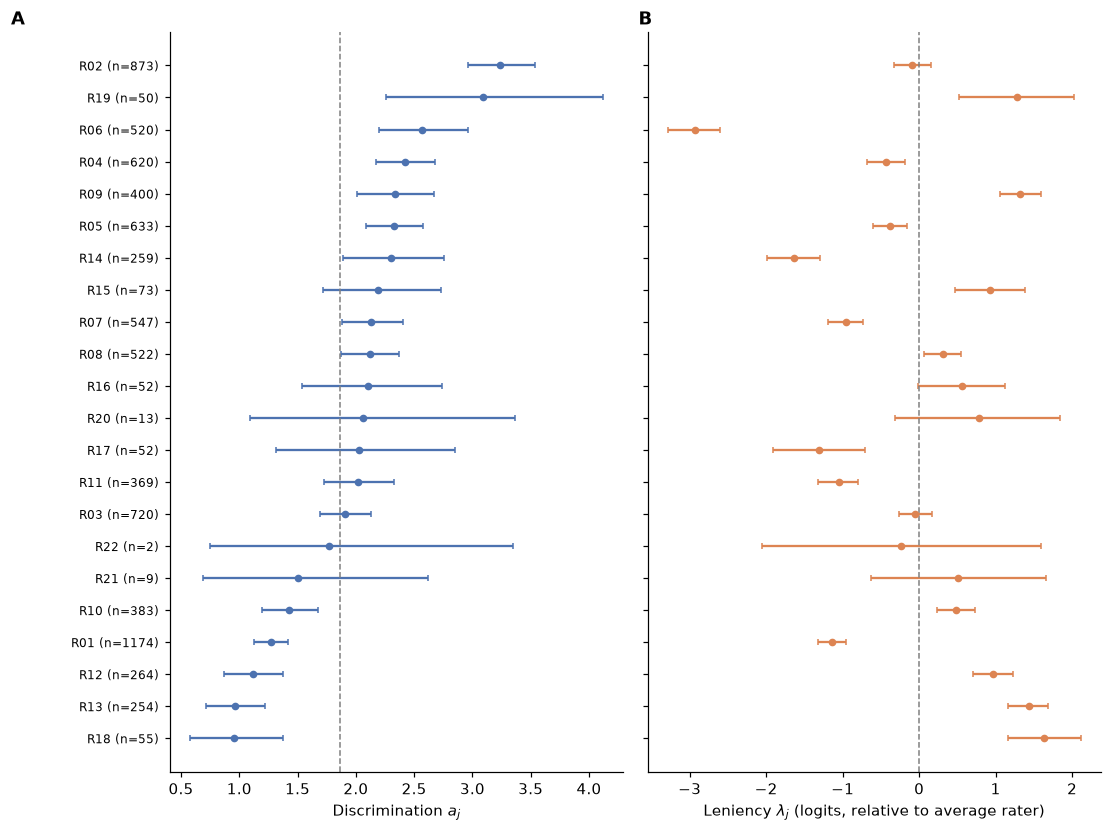

In [10]:
order = np.argsort(disc)
ypos = np.arange(len(order))
fig, axes = plt.subplots(1, 2, figsize=(10, 0.28 * len(order) + 1.5), sharey=True)
axes[0].errorbar(disc[order], ypos, xerr=[disc[order] - disc_low[order], disc_high[order] - disc[order]],
                 fmt="o", color="#4C72B0", ecolor="#4C72B0", capsize=2, ms=4)
axes[0].axvline(a_pool, color="grey", ls="--", lw=1)
axes[0].set_xlabel(r"Discrimination $a_j$")
axes[1].errorbar(len_mean[order], ypos, xerr=[len_mean[order] - len_low[order], len_high[order] - len_mean[order]],
                 fmt="o", color="#DD8452", ecolor="#DD8452", capsize=2, ms=4)
axes[1].axvline(0, color="grey", ls="--", lw=1)
axes[1].set_xlabel(r"Leniency $\lambda_j$ (logits, relative to average rater)")
axes[0].set_yticks(ypos)
axes[0].set_yticklabels([f"{rater_levels_o[i]} (n={jrt_rater_table.set_index('rater_id').loc[rater_levels_o[i], 'n_ratings']})"
                         for i in order], fontsize=8)
for ax, letter in zip(axes, "AB"):
    ax.text(-0.02 if letter == "B" else -0.35, 1.01, letter, transform=ax.transAxes, fontweight="bold", fontsize=12)
fig.tight_layout()
save_fig(fig, "fig_jrt_rater_parameters",
         "Rater parameters of the JRT model with 95% credible intervals: (A) discrimination a_j "
         "(dashed line: pool discrimination exp(mu_log_a)), (B) leniency lambda_j relative to the average rater (dashed line: 0). "
         "Raters are sorted by discrimination.")
plt.close(fig)

In [ ]:
#| label: fig-jrt-rater-parameters
#| fig-cap: "Rater parameters of the JRT model with 95% credible intervals: (A) discrimination a_j (dashed line: pool discrimination exp(mu_log_a)), (B) leniency lambda_j relative to the average rater (dashed line: 0). Raters are sorted by discrimination."
fig

Figure saved: fig_jrt_traceplots.png / fig_jrt_traceplots.svg


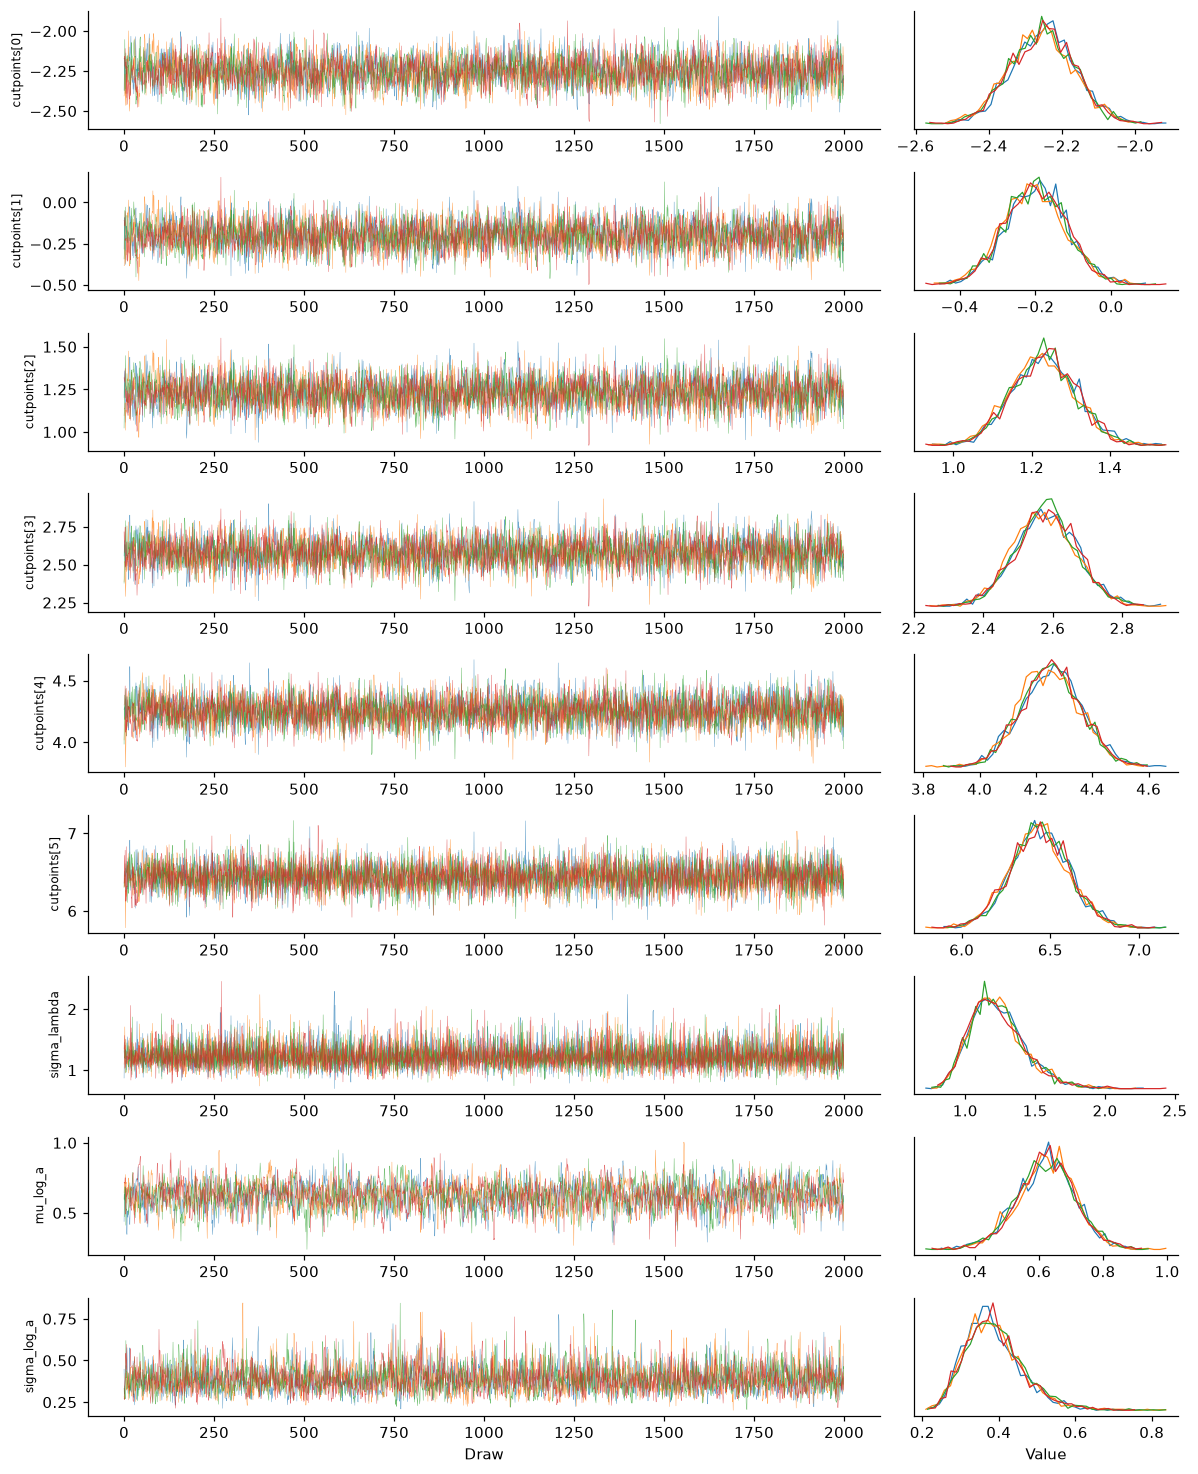

In [11]:
trace_vars = [("cutpoints", k) for k in range(6)] + [("sigma_lambda", None), ("mu_log_a", None), ("sigma_log_a", None)]
fig, axes = plt.subplots(len(trace_vars), 2, figsize=(11, 1.5 * len(trace_vars)),
                         gridspec_kw={"width_ratios": [3, 1]})
for row, (var, k) in enumerate(trace_vars):
    da = idata_jrt.posterior[var]
    vals = da.isel(cut=k).values if k is not None else da.values  # (chain, draw)
    label = f"{var}[{k}]" if k is not None else var
    for ch in range(vals.shape[0]):
        axes[row, 0].plot(vals[ch], lw=0.3, alpha=0.7)
        dens = np.histogram(vals[ch], bins=40, density=True)
        axes[row, 1].plot(0.5 * (dens[1][1:] + dens[1][:-1]), dens[0], lw=0.8)
    axes[row, 0].set_ylabel(label, fontsize=8)
    axes[row, 1].set_yticks([])
axes[-1, 0].set_xlabel("Draw")
axes[-1, 1].set_xlabel("Value")
fig.tight_layout()
save_fig(fig, "fig_jrt_traceplots",
         "Trace plots (left) and per-chain posterior densities (right) of the JRT thresholds and "
         "hyperparameters; colours denote the four chains.")
plt.close(fig)

In [ ]:
#| label: fig-jrt-traceplots
#| fig-cap: "Trace plots (left) and per-chain posterior densities (right) of the JRT thresholds and hyperparameters; colours denote the four chains."
fig

### 3.1 Posterior predictive check

Ratings are simulated from the posterior (every 10th draw). Observed category
frequencies, overall and per rater, are compared with the 95% posterior
predictive intervals.

Sampling: [y_obs]


Table saved: results/tables/jrt_ppc_category_shares.csv (7 rows x 6 columns)
Table saved: results/tables/jrt_ppc_rater_means.csv (22 rows x 6 columns)


Figure saved: fig_jrt_ppc.png / fig_jrt_ppc.svg


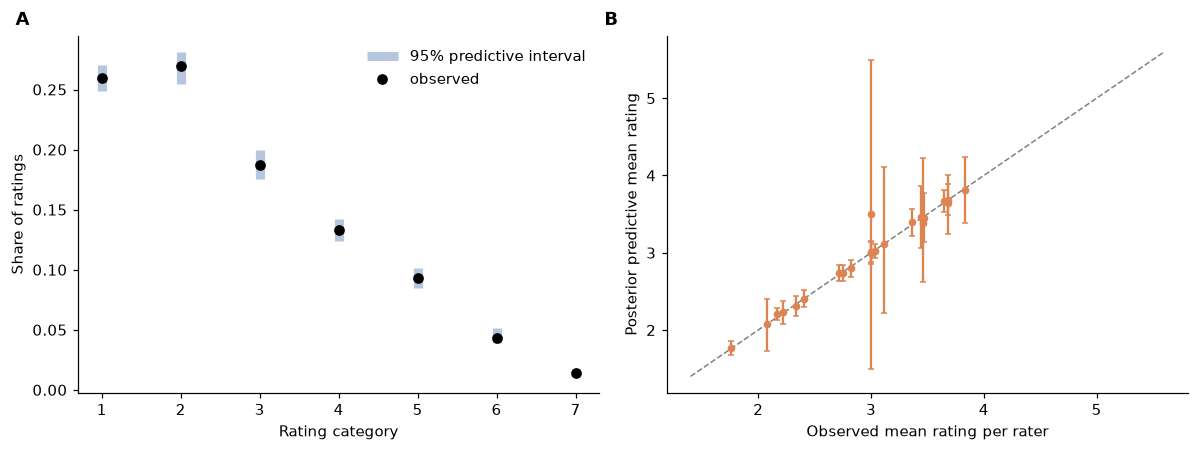

Categories with observed share inside the 95% PI: 7 of 7
Raters with observed mean inside the 95% PI: 22 of 22


In [12]:
posterior_thin = idata_jrt.posterior.isel(draw=slice(None, None, 10))
with jrt_model:
    ppc_jrt = pm.sample_posterior_predictive(posterior_thin, var_names=["y_obs"],
                                             random_seed=SEED, progressbar=False)
y_rep = np.asarray(ppc_jrt.posterior_predictive["y_obs"].values).reshape(-1, len(y_ord))  # (S, N)

obs_share = np.bincount(y_ord, minlength=7) / len(y_ord)
rep_share = np.stack([np.bincount(r, minlength=7) / len(y_ord) for r in y_rep])
rep_lo, rep_hi = np.quantile(rep_share, [0.025, 0.975], axis=0)

rater_codes = rater_idx_o
obs_rater_mean = np.array([y_ord[rater_codes == j].mean() + 1 for j in range(len(rater_levels_o))])
rep_rater_mean = np.stack([np.bincount(rater_codes, weights=r + 1, minlength=len(rater_levels_o))
                           / np.bincount(rater_codes, minlength=len(rater_levels_o)) for r in y_rep])
rr_lo, rr_mid, rr_hi = np.quantile(rep_rater_mean, [0.025, 0.5, 0.975], axis=0)

ppc_category = pd.DataFrame({"category": range(1, 8), "observed_share": obs_share,
                             "predicted_share_mean": rep_share.mean(axis=0),
                             "predicted_share_lower": rep_lo, "predicted_share_upper": rep_hi})
ppc_category["observed_within_95pi"] = (obs_share >= rep_lo) & (obs_share <= rep_hi)
save_table(ppc_category, "jrt_ppc_category_shares")
ppc_rater = pd.DataFrame({"rater_id": rater_levels_o, "observed_mean": obs_rater_mean,
                          "predicted_mean_median": rr_mid, "predicted_mean_lower": rr_lo,
                          "predicted_mean_upper": rr_hi})
ppc_rater["observed_within_95pi"] = (obs_rater_mean >= rr_lo) & (obs_rater_mean <= rr_hi)
save_table(ppc_rater, "jrt_ppc_rater_means")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
cats = np.arange(1, 8)
axes[0].vlines(cats, rep_lo, rep_hi, color="#4C72B0", lw=6, alpha=0.4, label="95% predictive interval")
axes[0].plot(cats, obs_share, "o", color="black", label="observed")
axes[0].set_xticks(cats)
axes[0].set_xlabel("Rating category")
axes[0].set_ylabel("Share of ratings")
axes[0].legend(frameon=False)
axes[1].errorbar(obs_rater_mean, rr_mid, yerr=[rr_mid - rr_lo, rr_hi - rr_mid], fmt="o",
                 color="#DD8452", capsize=2, ms=4)
lims = [min(obs_rater_mean.min(), rr_lo.min()) - 0.1, max(obs_rater_mean.max(), rr_hi.max()) + 0.1]
axes[1].plot(lims, lims, color="grey", ls="--", lw=1)
axes[1].set_xlabel("Observed mean rating per rater")
axes[1].set_ylabel("Posterior predictive mean rating")
for ax, letter in zip(axes, "AB"):
    ax.text(-0.12, 1.03, letter, transform=ax.transAxes, fontweight="bold", fontsize=12)
fig.tight_layout()
save_fig(fig, "fig_jrt_ppc",
         "Posterior predictive check of the JRT model: (A) observed share of each rating category "
         "(points) with the 95% posterior predictive interval (bars); (B) observed versus posterior "
         "predictive mean rating per rater, with 95% intervals (diagonal: perfect agreement).")
plt.close(fig)
print(f"Categories with observed share inside the 95% PI: {ppc_category['observed_within_95pi'].sum()} of 7")
print(f"Raters with observed mean inside the 95% PI: {ppc_rater['observed_within_95pi'].sum()} "
      f"of {len(ppc_rater)}")

In [ ]:
#| label: fig-jrt-ppc
#| fig-cap: "Posterior predictive check of the JRT model: (A) observed share of each rating category (points) with the 95% posterior predictive interval (bars); (B) observed versus posterior predictive mean rating per rater, with 95% intervals (diagonal: perfect agreement)."
fig

## 4. Test of the equal-discrimination constraint (LOO-CV)

The equal-discrimination model ($a_j = a$ for all raters, i.e.
$\sigma_{\log a} = 0$) is nested in the JRT model. It is fitted here with the
same function, data, priors and sampler settings. Both are compared by
Pareto-smoothed importance-sampling LOO-CV (Vehtari et al., 2017). The unit
left out is a single rating (pointwise over all ratings), so the comparison
asks how well each model predicts a new rating of an already rated action. A positive
`elpd_diff` (rater-specific minus equal discrimination) means better
out-of-sample prediction with rater-specific discrimination. Differences within
about 2 standard errors favour the simpler model on parsimony grounds.
Pareto-k values above 0.7 mark observations for which the approximation is
unreliable.

In [13]:
import gc

# Memory: keep only the pointwise LOO results of the JRT model and drop its log-likelihood
# (saved in the .nc file) before the second model is sampled.
loo_jrt = az.loo(idata_jrt, pointwise=True)
elpd_i_jrt = np.asarray(loo_jrt.elpd_i).ravel()
idata_jrt = idata_jrt.drop_nodes("log_likelihood")
gc.collect()

EQ_FIT_PATH = RESULTS_MODELS / "jrt_equal_discrimination_model.nc"
eq_model = build_jrt_model(equal_discrimination=True)
if USE_SAVED_FITS:
    idata_eq = az.from_netcdf(str(EQ_FIT_PATH))
    print(f"Loaded saved fit: {EQ_FIT_PATH.name}")
else:
    with eq_model:
        idata_eq = pm.sample(draws=N_DRAWS, tune=N_TUNE, chains=N_CHAINS, cores=N_CHAINS,
                             target_accept=TARGET_ACCEPT, random_seed=SEED, progressbar=False)
        pm.compute_log_likelihood(idata_eq, progressbar=False)
    idata_eq = shrink_log_likelihood(idata_eq)
    idata_eq.to_netcdf(str(EQ_FIT_PATH))

EQ_GROUPS = {k: v for k, v in PARAM_GROUPS.items()}
conv_eq, _ = convergence_by_group(idata_eq, EQ_GROUPS)
n_div_eq = int(idata_eq.sample_stats["diverging"].sum())
conv_eq.insert(0, "model", "equal discrimination")
save_table(conv_eq, "jrt_equal_discrimination_convergence")
max_rhat_eq = float(conv_eq["max_r_hat"].max())
min_ess_eq = float(conv_eq[["min_ess_bulk", "min_ess_tail"]].min().min())
print(f"Equal-discrimination model: divergences {n_div_eq}, max R-hat {max_rhat_eq:.4f}, "
      f"min ESS {min_ess_eq:.0f}")
if max_rhat_eq >= 1.01 or min_ess_eq < 400 or n_div_eq > 0:
    log_warning(f"Equal-discrimination model convergence: max R-hat {max_rhat_eq:.4f}, "
                f"min ESS {min_ess_eq:.0f}, divergences {n_div_eq}.")

loo_eq = az.loo(idata_eq, pointwise=True)
elpd_i_eq = np.asarray(loo_eq.elpd_i).ravel()
# Release the equal-discrimination model; everything below uses only the JRT model.
del idata_eq, eq_model
gc.collect()
diff_i = elpd_i_jrt - elpd_i_eq
elpd_diff = float(diff_i.sum())
se_diff = float(np.sqrt(len(diff_i) * np.var(diff_i)))

loo_comparison = pd.DataFrame({
    "model": ["JRT, equal discrimination (a_j = a)",
              "JRT, rater-specific discrimination (a_j)"],
    "elpd_loo": [float(loo_eq.elpd), float(loo_jrt.elpd)],
    "se": [float(loo_eq.se), float(loo_jrt.se)],
    "p_loo": [float(loo_eq.p), float(loo_jrt.p)],
    "elpd_diff_vs_equal": [0.0, elpd_diff],
    "se_diff_vs_equal": [0.0, se_diff],
    "share_pareto_k_gt_0.7": [float((np.asarray(loo_eq.pareto_k) > 0.7).mean()),
                              float((np.asarray(loo_jrt.pareto_k) > 0.7).mean())],
})
save_table(loo_comparison, "jrt_loo_comparison")
print(f"elpd_diff (rater-specific - equal discrimination) = {elpd_diff:.1f}, SE = {se_diff:.1f}, "
      f"ratio = {elpd_diff / se_diff:.1f}")
if (loo_comparison["share_pareto_k_gt_0.7"] > 0.05).any():
    log_warning("More than 5% of observations have Pareto-k > 0.7 - LOO is unreliable for these.")

/home/mklemp/jrt/.venv-jrt/lib/python3.12/site-packages/arviz_stats/loo/helper_loo.py:1146: UserWarning: Estimated shape parameter of Pareto distribution is greater than 0.70 for one or more samples. You should consider using a more robust model, this is because importance sampling is less likely to work well if the marginal posterior and LOO posterior are very different. This is more likely to happen with a non-robust model and highly influential observations.
  warnings.warn(


Initializing NUTS using jitter+adapt_diag...


Multiprocess sampling (4 chains in 4 jobs)


NUTS: [theta, sigma_lambda, leniency, mu_log_a, cutpoints]


Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 283 seconds.


Table saved: results/tables/jrt_equal_discrimination_convergence.csv (5 rows x 6 columns)
Equal-discrimination model: divergences 0, max R-hat 1.0038, min ESS 1552


/home/mklemp/jrt/.venv-jrt/lib/python3.12/site-packages/arviz_stats/loo/helper_loo.py:1146: UserWarning: Estimated shape parameter of Pareto distribution is greater than 0.70 for one or more samples. You should consider using a more robust model, this is because importance sampling is less likely to work well if the marginal posterior and LOO posterior are very different. This is more likely to happen with a non-robust model and highly influential observations.
  warnings.warn(


Table saved: results/tables/jrt_loo_comparison.csv (2 rows x 7 columns)
elpd_diff (rater-specific - equal discrimination) = 163.3, SE = 19.7, ratio = 8.3


,model,elpd_loo,se,p_loo,elpd_diff_vs_equal,se_diff_vs_equal,share_pareto_k_gt_0.7
0,"JRT, equal discrimination (a_j = a)",-11701.185353,62.843365,2375.876715,0.000000,0.000000,0.001402
1,"JRT, rater-specific discrimination (a_j)",-11537.930567,65.516591,2573.685792,163.254786,19.684919,0.028047


In [ ]:
#| label: tbl-jrt-equal-discrimination-loo
#| tbl-cap: "PSIS-LOO comparison of the JRT model with rater-specific discrimination and the nested equal-discrimination model."
show_table(loo_comparison, 3)

## 5. Judge category curves and information functions

For the raters with the lowest, median and highest discrimination: the
category probabilities $P(Y=k\mid\theta)$ and the graded-response Fisher
information (Samejima, 1969). With $P^*_k(\theta)=\Pr(Y>k\mid\theta)$
(where $P^*_0=1$ and $P^*_7=0$):

$$
I_j(\theta) = \sum_{k=1}^{7}\frac{\big[P^{*\prime}_{k-1}(\theta)-P^{*\prime}_{k}(\theta)\big]^2}{P_k(\theta)},
\qquad P^{*\prime}_k = a_j\,P^*_k\,(1-P^*_k)
$$

Figure saved: fig_jrt_category_curves_information.png / fig_jrt_category_curves_information.svg


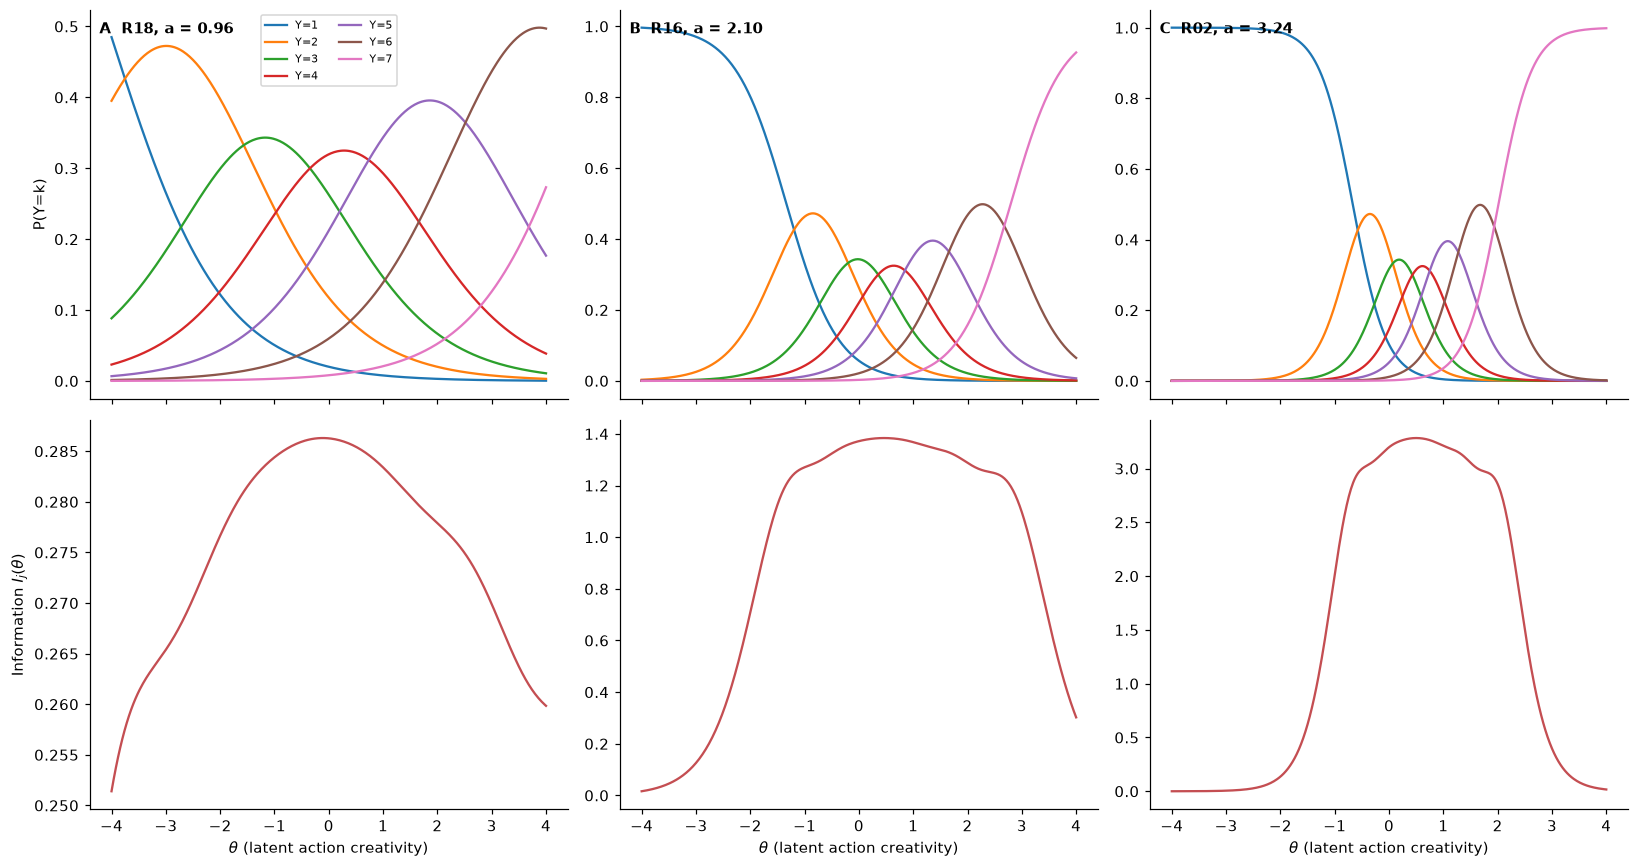

Table saved: results/tables/jrt_information_by_rater.csv (22 rows x 6 columns)


,rater_id,discrimination,leniency,peak_information,theta_at_peak,information_at_theta_0
0,R01,1.270,-1.134,0.504,2.10,0.469
1,R02,3.241,-0.089,3.284,0.50,3.198
2,R03,1.907,-0.051,1.137,0.82,1.109
3,R04,2.422,-0.431,1.834,0.80,1.759
4,R05,2.323,-0.383,1.688,0.82,1.623
5,R06,2.570,-2.928,2.065,1.74,1.515
6,R07,2.134,-0.956,1.423,1.16,1.333
7,R08,2.119,0.306,1.403,0.58,1.384
8,R09,2.334,1.323,1.703,0.08,1.702
9,R10,1.430,0.477,0.640,0.74,0.633


In [14]:
def category_probs_and_info(theta_grid, a, lam, cuts):
    eta = a * theta_grid + lam
    p_gt = 1 / (1 + np.exp(-(eta[:, None] - cuts[None, :])))          # P(Y > k), k = 1..6
    ones, zeros = np.ones((len(theta_grid), 1)), np.zeros((len(theta_grid), 1))
    p_star = np.concatenate([ones, p_gt, zeros], axis=1)               # k = 0..7
    probs = p_star[:, :-1] - p_star[:, 1:]                             # (n_theta, 7)
    d_star = a * p_star * (1 - p_star)
    d_probs = d_star[:, :-1] - d_star[:, 1:]
    info = np.sum(d_probs ** 2 / np.clip(probs, 1e-12, None), axis=1)
    return probs, info

theta_grid = np.linspace(-4, 4, 401)
cut_mean_jrt = idata_jrt.posterior["cutpoints"].mean(dim=("chain", "draw")).values
lam_mean_jrt = len_mean

info_by_rater = np.array([category_probs_and_info(theta_grid, disc[j], lam_mean_jrt[j], cut_mean_jrt)[1]
                          for j in range(len(disc))])                 # (n_raters, n_theta)

example_raters_idx = [int(np.argmin(disc)), int(np.argsort(disc)[len(disc) // 2]), int(np.argmax(disc))]
example_labels = ["lowest discrimination", "median discrimination", "highest discrimination"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True)
for col, (ridx, label) in enumerate(zip(example_raters_idx, example_labels)):
    probs, info = category_probs_and_info(theta_grid, disc[ridx], lam_mean_jrt[ridx], cut_mean_jrt)
    for k in range(7):
        axes[0, col].plot(theta_grid, probs[:, k], label=f"Y={k+1}")
    axes[0, col].text(0.02, 0.97, f"{'ABC'[col]}  {rater_levels_o[ridx]}, a = {disc[ridx]:.2f}",
                      transform=axes[0, col].transAxes, va="top", fontweight="bold")
    axes[1, col].plot(theta_grid, info, color="#C44E52")
    axes[1, col].set_xlabel(r"$\theta$ (latent action creativity)")
axes[0, 0].set_ylabel("P(Y=k)")
axes[0, 0].legend(fontsize=7, ncol=2)
axes[1, 0].set_ylabel(r"Information $I_j(\theta)$")
fig.tight_layout()
save_fig(fig, "fig_jrt_category_curves_information",
         "Category probabilities (top) and graded-response Fisher information (bottom) for the "
         "raters with the lowest (A), median (B) and highest (C) JRT discrimination.")
plt.close(fig)

peak_idx = info_by_rater.argmax(axis=1)
info_table = pd.DataFrame({
    "rater_id": rater_levels_o,
    "discrimination": disc,
    "leniency": len_mean,
    "peak_information": info_by_rater.max(axis=1),
    "theta_at_peak": theta_grid[peak_idx],
    "information_at_theta_0": info_by_rater[:, np.argmin(np.abs(theta_grid))],
}).sort_values("rater_id").reset_index(drop=True)
save_table(info_table, "jrt_information_by_rater")

In [ ]:
#| label: fig-jrt-category-curves-information
#| fig-cap: "Category probabilities (top) and graded-response Fisher information (bottom) for the raters with the lowest (A), median (B) and highest (C) JRT discrimination."
fig

In [ ]:
#| label: tbl-jrt-information-by-rater
#| tbl-cap: "Graded-response information by rater: peak information, the latent creativity level at the peak, and information at theta = 0."
show_table(info_table, 3)

## 6. Score reliability

**Marginal reliability as a function of the number of judges (IRT D-study).**
An action rated by $k$ randomly drawn judges has expected information
$I_k(\theta) = k\cdot\bar I(\theta)$, where $\bar I$ is the mean information
across the rater pool. With $\theta \sim \mathcal N(0,1)$, the marginal
reliability is (Green et al., 1984):

$$
\bar\rho_k = \frac{1}{1 + \int \varphi(\theta)\, I_k(\theta)^{-1}\, d\theta}
$$

Uncertainty is propagated by recomputing $\bar I$ and $\bar\rho_k$ for 1,000
posterior draws (95% credible intervals). Because the pool is unbalanced, the
D-study is also computed with raters weighted by their share of the realised
ratings instead of equally.

**Empirical reliability** of the scores actually estimated:
$\operatorname{Var}(\hat\theta)/[\operatorname{Var}(\hat\theta)+\overline{\mathrm{PSD}^2}]$.

Table saved: results/tables/jrt_marginal_reliability.csv (11 rows x 3 columns)


Empirical reliability of the JRT scores: 0.660
Marginal reliability at the harmonic-mean k = 1.73: 0.646


Figure saved: fig_jrt_information_reliability.png / fig_jrt_information_reliability.svg


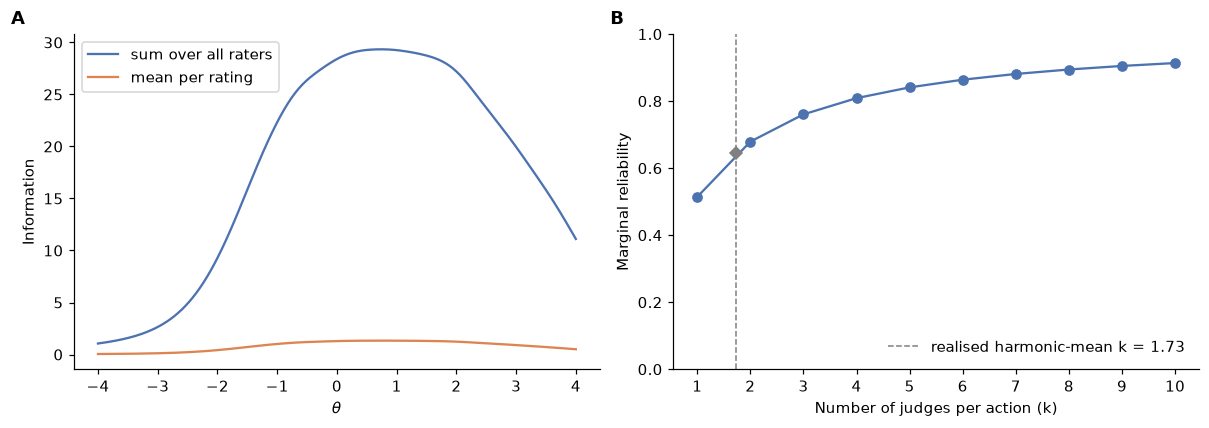

In [15]:
from scipy.stats import norm

phi_weights = norm.pdf(theta_grid)
phi_weights = phi_weights / phi_weights.sum()
mean_info = info_by_rater.mean(axis=0)

n_per_action_jrt = df_ord.groupby("action_id").size()
k_harmonic = float(len(n_per_action_jrt) / (1.0 / n_per_action_jrt).sum())
k_list = list(range(1, 11)) + [k_harmonic]
k_type = ["integer"] * 10 + ["harmonic mean (realised)"]

def marginal_reliability(k, info=None):
    info = mean_info if info is None else info
    return 1.0 / (1.0 + np.sum(phi_weights / (k * info)))

# Rater weights: equal (a random judge from the pool) or proportional to the realised
# number of ratings (the judge mix of the present design).
w_ratings = np.bincount(rater_idx_o, minlength=len(rater_levels_o)) / len(rater_idx_o)
mean_info_weighted = w_ratings @ info_by_rater

# Posterior uncertainty: recompute information and reliability for 1,000 posterior draws.
N_REL_DRAWS = 1000
post_flat = {v: idata_jrt.posterior[v].stack(sample=("chain", "draw")).transpose("sample", ...).values
             for v in ["discrimination", "leniency", "cutpoints"]}
n_total_draws = post_flat["discrimination"].shape[0]
rel_idx = np.random.default_rng(SEED).choice(n_total_draws, min(N_REL_DRAWS, n_total_draws), replace=False)
rel_draws = {"equal": [], "ratings": []}
for s in rel_idx:
    info_s = np.array([category_probs_and_info(theta_grid, post_flat["discrimination"][s, j],
                                               post_flat["leniency"][s, j], post_flat["cutpoints"][s])[1]
                       for j in range(len(rater_levels_o))])
    rel_draws["equal"].append([marginal_reliability(k, info_s.mean(axis=0)) for k in k_list])
    rel_draws["ratings"].append([marginal_reliability(k, w_ratings @ info_s) for k in k_list])
rel_draws = {key: np.array(val) for key, val in rel_draws.items()}

jrt_d_study = pd.DataFrame({
    "k": k_list, "k_type": k_type,
    "marginal_reliability": [marginal_reliability(k) for k in k_list],
    "marginal_reliability_lower": np.quantile(rel_draws["equal"], 0.025, axis=0),
    "marginal_reliability_upper": np.quantile(rel_draws["equal"], 0.975, axis=0),
    "marginal_reliability_rating_weighted": [marginal_reliability(k, mean_info_weighted) for k in k_list],
    "rating_weighted_lower": np.quantile(rel_draws["ratings"], 0.025, axis=0),
    "rating_weighted_upper": np.quantile(rel_draws["ratings"], 0.975, axis=0),
})
save_table(jrt_d_study, "jrt_marginal_reliability")

theta_post_jrt = idata_jrt.posterior["theta"]
theta_jrt_mean = theta_post_jrt.mean(dim=("chain", "draw")).values
theta_jrt_sd = theta_post_jrt.std(dim=("chain", "draw")).values
empirical_reliability = float(np.var(theta_jrt_mean, ddof=1)
                              / (np.var(theta_jrt_mean, ddof=1) + np.mean(theta_jrt_sd ** 2)))
print(f"Empirical reliability of the JRT scores: {empirical_reliability:.3f}")
hm = jrt_d_study.iloc[-1]
print(f"Marginal reliability at the harmonic-mean k = {k_harmonic:.2f}: "
      f"{hm['marginal_reliability']:.3f} [{hm['marginal_reliability_lower']:.3f}, "
      f"{hm['marginal_reliability_upper']:.3f}]")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(theta_grid, info_by_rater.sum(axis=0), color="#4C72B0", label="sum over all raters")
axes[0].plot(theta_grid, mean_info, color="#DD8452", label="mean per rating")
axes[0].set_xlabel(r"$\theta$")
axes[0].set_ylabel("Information")
axes[0].legend(frameon=False)
sub = jrt_d_study[jrt_d_study["k_type"] == "integer"]
axes[1].fill_between(sub["k"], sub["marginal_reliability_lower"], sub["marginal_reliability_upper"],
                     color="#4C72B0", alpha=0.2, label="95% credible interval")
axes[1].plot(sub["k"], sub["marginal_reliability"], marker="o", color="#4C72B0", label="equal rater weights")
axes[1].plot(sub["k"], sub["marginal_reliability_rating_weighted"], marker="s", ms=4, ls=":",
             color="#55A868", label="weighted by realised ratings")
axes[1].axvline(k_harmonic, color="grey", ls="--", lw=1, label=f"realised harmonic-mean k = {k_harmonic:.2f}")
axes[1].set_xticks(range(1, 11))
axes[1].set_ylim(0, 1)
axes[1].set_xlabel("Number of judges per action (k)")
axes[1].set_ylabel("Marginal reliability")
axes[1].legend(frameon=False, loc="lower right", fontsize=8)
for ax, letter in zip(axes, "AB"):
    ax.text(-0.12, 1.03, letter, transform=ax.transAxes, fontweight="bold", fontsize=12)
fig.tight_layout()
save_fig(fig, "fig_jrt_information_reliability",
         "(A) Information of the rater pool across the latent creativity continuum (sum over all "
         "raters and mean per rating). (B) Marginal reliability of theta as a function of the number "
         "of judges per action (IRT D-study) with 95% credible intervals (equal rater weights) and "
         "with raters weighted by their share of the realised ratings; the dashed line marks the "
         "realised harmonic-mean number of ratings per action.")
plt.close(fig)

In [ ]:
#| label: fig-jrt-information-reliability
#| fig-cap: "(A) Information of the rater pool across the latent creativity continuum (sum over all raters and mean per rating). (B) Marginal reliability of theta as a function of the number of judges per action (IRT D-study) with 95% credible intervals (equal rater weights) and with raters weighted by their share of the realised ratings; the dashed line marks the realised harmonic-mean number of ratings per action."
fig

In [16]:
#| label: tbl-jrt-d-study
#| tbl-cap: "Marginal reliability of the JRT scores by number of judges per action (IRT D-study), with 95% credible intervals, for equal rater weights and for raters weighted by their share of the realised ratings."
show_table(jrt_d_study, 3)

,k,k_type,marginal_reliability
0,1.000,integer,0.514
1,2.000,integer,0.679
2,3.000,integer,0.760
3,4.000,integer,0.809
4,5.000,integer,0.841
5,6.000,integer,0.864
6,7.000,integer,0.881
7,8.000,integer,0.894
8,9.000,integer,0.905
9,10.000,integer,0.914


In [17]:
theta_lo = theta_post_jrt.quantile(0.025, dim=("chain", "draw")).values
theta_hi = theta_post_jrt.quantile(0.975, dim=("chain", "draw")).values
n_ratings_by_action = n_per_action_jrt.reindex(action_levels_o).values
score_precision = (pd.DataFrame({"n_ratings": n_ratings_by_action, "posterior_sd": theta_jrt_sd,
                                 "ci_width": theta_hi - theta_lo})
                   .assign(n_ratings_group=lambda d: np.where(d["n_ratings"] >= 5, "5+", d["n_ratings"].astype(str)))
                   .groupby("n_ratings_group")
                   .agg(n_actions=("posterior_sd", "size"),
                        mean_posterior_sd=("posterior_sd", "mean"),
                        min_posterior_sd=("posterior_sd", "min"),
                        max_posterior_sd=("posterior_sd", "max"),
                        mean_ci_width=("ci_width", "mean"))
                   .reset_index())
save_table(score_precision, "jrt_score_precision_by_n")
print(f"Score posterior mean: SD across actions = {np.std(theta_jrt_mean, ddof=1):.3f}, "
      f"range = [{theta_jrt_mean.min():.2f}, {theta_jrt_mean.max():.2f}]")

Table saved: results/tables/jrt_score_precision_by_n.csv (5 rows x 6 columns)
Score posterior mean: SD across actions = 0.813, range = [-2.08, 3.08]


,n_ratings_group,n_actions,mean_posterior_sd,min_posterior_sd,max_posterior_sd,mean_ci_width
0,1,898,0.651,0.456,0.948,2.576
1,2,2080,0.572,0.371,0.863,2.257
2,3,357,0.503,0.353,0.717,1.982
3,4,123,0.444,0.332,0.697,1.748
4,5+,211,0.400,0.258,0.584,1.569


In [ ]:
#| label: tbl-jrt-score-precision
#| tbl-cap: "Precision of the JRT action scores by number of ratings per action: number of actions, mean and range of the posterior SD of theta, and mean width of the 95% credible interval."
show_table(score_precision, 3)

In [18]:
cut_gaps = np.diff(cut_mean_jrt)
derived = {
    "n_raters": len(rater_levels_o),
    "pool_discrimination_exp_mu_log_a": a_pool,
    "n_raters_discrimination_ci_excludes_pool": int(((log_a_dev_low > 0) | (log_a_dev_high < 0)).sum()),
    "n_raters_discrimination_ci_above_pool": int((log_a_dev_low > 0).sum()),
    "n_raters_discrimination_ci_below_pool": int((log_a_dev_high < 0).sum()),
    "n_raters_discrimination_lt_0.5": int((disc < 0.5).sum()),
    "n_raters_leniency_ci_excludes_0": int(((len_low > 0) | (len_high < 0)).sum()),
    "n_raters_leniency_ci_above_0": int((len_low > 0).sum()),
    "n_raters_leniency_ci_below_0": int((len_high < 0).sum()),
    "ratio_max_min_discrimination": float(disc.max() / disc.min()),
    "share_ratings_categories_1_2": float(np.isin(y_ord, [0, 1]).mean()),
    "share_ratings_categories_6_7": float(np.isin(y_ord, [5, 6]).mean()),
    **{f"threshold_gap_{k + 1}_{k + 2}": float(g) for k, g in enumerate(cut_gaps)},
    "theta_pool_mean_information_peak": float(theta_grid[np.argmax(mean_info)]),
    "pool_mean_information_peak": float(mean_info.max()),
}
derived_counts = pd.DataFrame({"quantity": list(derived), "value": list(derived.values())})
save_table(derived_counts, "jrt_derived_counts")

Table saved: results/tables/jrt_derived_counts.csv (19 rows x 2 columns)


,quantity,value
0,n_raters,22.000000
1,pool_discrimination_exp_mu_log_a,1.868080
2,n_raters_discrimination_ci_excludes_pool,11.000000
3,n_raters_discrimination_ci_above_pool,6.000000
4,n_raters_discrimination_ci_below_pool,5.000000
5,n_raters_discrimination_lt_0.5,0.000000
6,n_raters_leniency_ci_excludes_0,16.000000
7,n_raters_leniency_ci_above_0,8.000000
8,n_raters_leniency_ci_below_0,8.000000
9,ratio_max_min_discrimination,3.386618


In [ ]:
#| label: tbl-jrt-derived-counts
#| tbl-cap: "Derived quantities of the JRT model used in the text."
show_table(derived_counts, 3)

## 7. Export in the standard format

`score` is the posterior mean of θ (scale fixed to N(0, 1)). The rater table
contains discrimination and leniency (relative to the average rater), each
with credible intervals. Actions outside the largest component get `NaN`.

In [19]:
scores_jrt = pd.DataFrame({
    "action_id": action_levels_o,
    "score": theta_jrt_mean,
    "score_se": theta_jrt_sd,
    "score_lower": theta_post_jrt.quantile(0.025, dim=("chain", "draw")).values,
    "score_upper": theta_post_jrt.quantile(0.975, dim=("chain", "draw")).values,
})
action_base = (ratings_clean.groupby("action_id")
               .agg(n_ratings=("rating_numeric", "size"),
                    connected_component=("connected_component", "first"))
               .reset_index())
action_base["in_largest_component"] = action_base["connected_component"] == 0
scores_jrt = action_base.merge(scores_jrt, on="action_id", how="left")
save_table(scores_jrt, "scores_jrt")

raters_jrt = jrt_rater_table.copy()
save_table(raters_jrt, "raters_jrt")

save_diagnostics({
    "n_draws_per_chain": N_DRAWS, "n_tune": N_TUNE, "n_chains": N_CHAINS,
    "max_rhat": max_rhat_jrt, "n_divergences": n_div_jrt, "min_ess_bulk": min_ess_jrt,
    "min_ess_tail": min_ess_tail_jrt,
    "max_rhat_equal_discrimination": max_rhat_eq, "n_divergences_equal_discrimination": n_div_eq,
    "median_discrimination": float(np.median(disc)),
    "min_discrimination": float(disc.min()), "max_discrimination": float(disc.max()),
    "n_raters_discrimination_lt_0.5": int((disc < 0.5).sum()),
    "elpd_diff_rater_specific_minus_equal": elpd_diff, "elpd_diff_se": se_diff,
    "empirical_reliability": empirical_reliability,
    "k_harmonic": k_harmonic,
    "marginal_reliability_k1": marginal_reliability(1),
    "marginal_reliability_k_harmonic": marginal_reliability(k_harmonic),
    "n_components": n_components,
})

Table saved: results/tables/scores_jrt.csv (3669 rows x 8 columns)
Table saved: results/tables/raters_jrt.csv (22 rows x 12 columns)
Table saved: results/tables/model_diagnostics_jrt.csv (20 rows x 2 columns)


PosixPath('/home/mklemp/jrt/results/tables/model_diagnostics_jrt.csv')

## Warnings collected in this notebook

In [20]:
warnings_df = pd.DataFrame(WARNINGS_LOG, columns=["notebook", "timestamp", "message"])
save_table(warnings_df, f"warnings_log_{NOTEBOOK_KEY}")
print(f"{len(warnings_df)} warnings collected in this notebook.")
for msg in warnings_df["message"]:
    print(f"  - {msg}")

Table saved: results/tables/warnings_log_jrt.csv (0 rows x 3 columns)
0 warnings collected in this notebook.
